<a href="https://colab.research.google.com/github/Ysabellyysa/Python/blob/main/GAN_Fashion_MNIST_Pratica_Pr%C3%A1tica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import fashion_mnist
from matplotlib import pyplot as plt

tf.random.set_seed(1)
print("GPUs disponíveis: ", len(tf.config.list_physical_devices('GPU')))

GPUs disponíveis:  1


In [2]:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


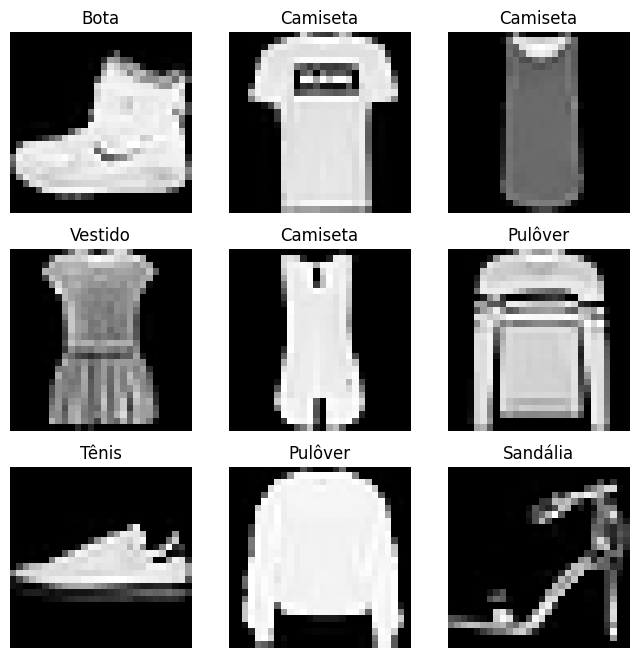

In [3]:
# imagens reais
nomes = ["Camiseta", "Calça", "Pulôver", "Vestido", "Casaco",
         "Sandália", "Camisa", "Tênis", "Bolsa", "Bota"]

plt.figure(figsize=(8, 8))
for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.imshow(x_train[i], cmap="Greys_r")
    plt.title(nomes[y_train[i]])
    plt.axis("off")
plt.show()

In [4]:
# une treino e teste
dataset = np.concatenate([x_train, x_test], axis=0)

# normaliza
dataset = np.expand_dims(dataset, -1).astype("float32") / 255 # adiciona o canal e deixa entre 0 e 1

In [5]:
BATCH_SIZE = 64

dataset = tf.data.Dataset.from_tensor_slices(dataset)
dataset = dataset.shuffle(buffer_size=1024).batch(BATCH_SIZE) # embaralha e divide em lotes

In [6]:
NOISE_DIM = 150 # tamanho do ruído que entra no gerador

# gerador: transforma ruído em imagem

generator = keras.models.Sequential([
    keras.Input(shape=(NOISE_DIM,)),
    layers.Dense(7*7*256),
    layers.Reshape(target_shape=(7, 7, 256)),
    layers.Conv2DTranspose(256, 3, strides=2, padding="same"), # strides=2 dobra o tamanho (7 -> 14)
    layers.LeakyReLU(),
    layers.Conv2DTranspose(128, 3, strides=2, padding="same"), # 14 -> 28
    layers.LeakyReLU(),
    layers.Conv2DTranspose(1, 3, activation="sigmoid", padding="same")
], name="generator")

generator.summary()

Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12544)          │     1,894,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 256)    │       590,080 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 128)    │       295,040 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │         1,153 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,780,417 (10.61 MB)

 Trainable params: 2,780,417 (10.61 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# discriminador: diz se a imagem é real ou falsa
discriminator = keras.models.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(64, 3, strides=2, padding="same"),
    layers.LeakyReLU(),
    layers.Conv2D(128, 3, strides=2, padding="same"),
    layers.LeakyReLU(),
    layers.Flatten(),
    layers.Dense(1, activation="sigmoid") # saída: probabilidade de ser real
], name="discriminator")

discriminator.summary()

Model: "discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 80,769 (315.50 KB)

 Trainable params: 80,769 (315.50 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# um otimizador para cada rede
optimizerG = keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)
optimizerD = keras.optimizers.Adam(learning_rate=0.0001, beta_1=0.5)

lossFn = keras.losses.BinaryCrossentropy() # real ou falso
# métricas de acerto
gAccMetric = keras.metrics.BinaryAccuracy()
dAccMetric = keras.metrics.BinaryAccuracy()

In [9]:
@tf.function
def trainDStep(data):
    batchSize = tf.shape(data)[0]
    noise = tf.random.normal(shape=(batchSize, NOISE_DIM)) # ruído para o gerador

    # 1 real, 0 falso
    y_true = tf.concat([tf.ones((batchSize, 1)), tf.zeros((batchSize, 1))], axis=0)

    with tf.GradientTape() as tape:
        fake = generator(noise) # imagens falsas
        x = tf.concat([data, fake], axis=0) # junta reais e falsas
        y_pred = discriminator(x)
        discriminatorLoss = lossFn(y_true, y_pred)

    # atualiza só os pesos do discriminador
    grads = tape.gradient(discriminatorLoss, discriminator.trainable_weights)
    optimizerD.apply_gradients(zip(grads, discriminator.trainable_weights))
    dAccMetric.update_state(y_true, y_pred)

    return {"discriminator_loss": discriminatorLoss,
            "discriminator_accuracy": dAccMetric.result()}

In [10]:
@tf.function
def trainGStep(data):
    batchSize = tf.shape(data)[0]
    noise = tf.random.normal(shape=(batchSize, NOISE_DIM))

    # quer ser classificado como real
    y_true = tf.ones((batchSize, 1))

    with tf.GradientTape() as tape:
        y_pred = discriminator(generator(noise)) # o discriminador avalia as imagens falsas
        generatorLoss = lossFn(y_true, y_pred)

    # atualiza só os pesos do gerador
    grads = tape.gradient(generatorLoss, generator.trainable_weights)
    optimizerG.apply_gradients(zip(grads, generator.trainable_weights))
    gAccMetric.update_state(y_true, y_pred)

    return {"generator_loss": generatorLoss,
            "generator_accuracy": gAccMetric.result()}

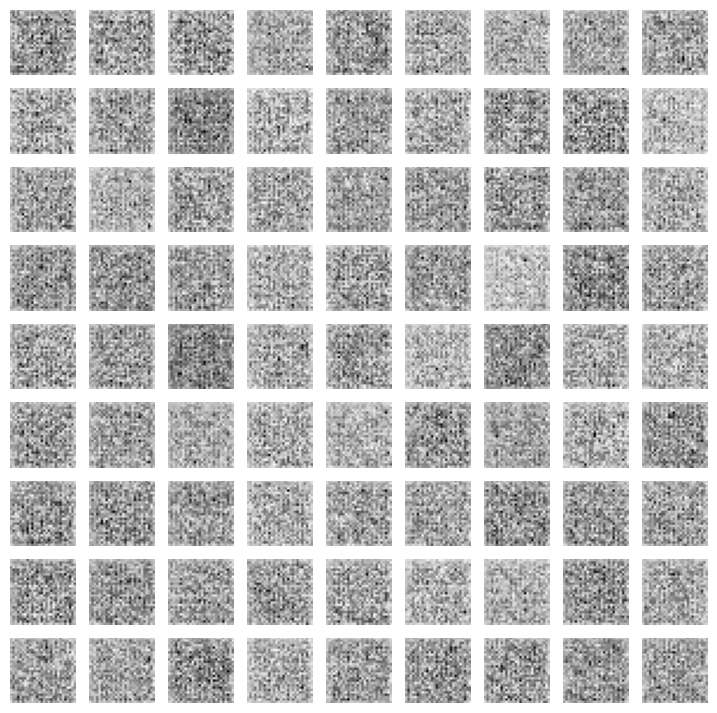

In [11]:
def plotarImagens(model, n=9):
    images = model(tf.random.normal(shape=(n * n, NOISE_DIM))) # gera n*n imagens a partir de ruído

    plt.figure(figsize=(9, 9))
    for i, image in enumerate(images):
        plt.subplot(n, n, i+1)
        plt.imshow(np.squeeze(image, -1), cmap="Greys_r")
        plt.axis("off")
    plt.show()

plotarImagens(generator)

Época: 0, Perda G: 0.7022, Perda D: 0.6888, Acc G: 37.75%, Acc D: 56.95%
Época: 1, Perda G: 0.7074, Perda D: 0.6850, Acc G: 40.30%, Acc D: 54.98%
Época: 2, Perda G: 0.6993, Perda D: 0.6929, Acc G: 40.64%, Acc D: 55.15%
Época: 3, Perda G: 0.6979, Perda D: 0.6936, Acc G: 42.39%, Acc D: 53.86%
Época: 4, Perda G: 0.6977, Perda D: 0.6933, Acc G: 43.46%, Acc D: 53.09%
Época: 5, Perda G: 0.6977, Perda D: 0.6930, Acc G: 44.01%, Acc D: 52.69%
Época: 6, Perda G: 0.6977, Perda D: 0.6928, Acc G: 44.39%, Acc D: 52.42%
Época: 7, Perda G: 0.6980, Perda D: 0.6928, Acc G: 44.60%, Acc D: 52.23%
Época: 8, Perda G: 0.6970, Perda D: 0.6927, Acc G: 44.79%, Acc D: 52.08%
Época: 9, Perda G: 0.6976, Perda D: 0.6927, Acc G: 44.94%, Acc D: 51.97%


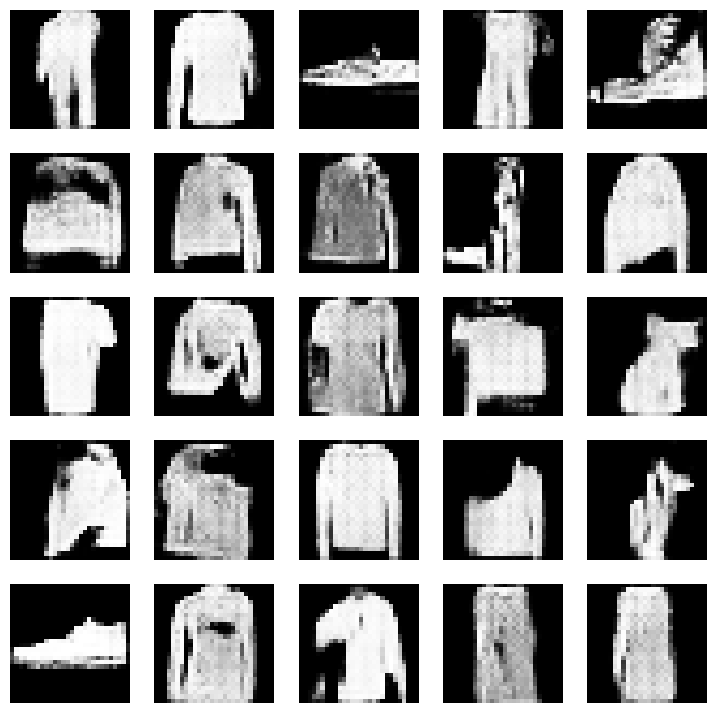

Época: 10, Perda G: 0.6977, Perda D: 0.6926, Acc G: 45.07%, Acc D: 51.86%
Época: 11, Perda G: 0.6979, Perda D: 0.6926, Acc G: 45.14%, Acc D: 51.79%
Época: 12, Perda G: 0.6973, Perda D: 0.6925, Acc G: 45.26%, Acc D: 51.72%
Época: 13, Perda G: 0.6972, Perda D: 0.6926, Acc G: 45.34%, Acc D: 51.66%
Época: 14, Perda G: 0.6972, Perda D: 0.6925, Acc G: 45.46%, Acc D: 51.61%
Época: 15, Perda G: 0.6977, Perda D: 0.6925, Acc G: 45.50%, Acc D: 51.57%
Época: 16, Perda G: 0.6977, Perda D: 0.6925, Acc G: 45.56%, Acc D: 51.53%
Época: 17, Perda G: 0.6973, Perda D: 0.6924, Acc G: 45.58%, Acc D: 51.51%
Época: 18, Perda G: 0.6975, Perda D: 0.6924, Acc G: 45.58%, Acc D: 51.49%
Época: 19, Perda G: 0.6975, Perda D: 0.6924, Acc G: 45.62%, Acc D: 51.47%


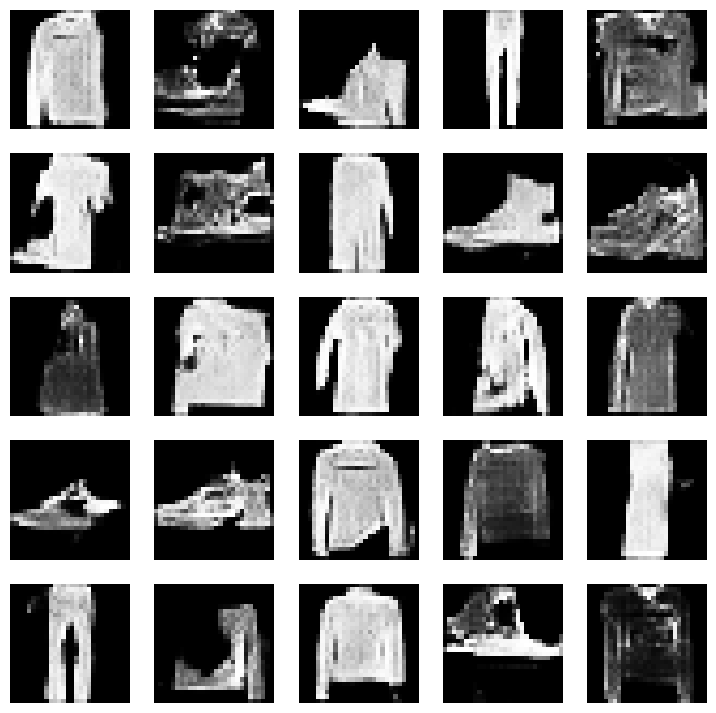

Época: 20, Perda G: 0.6975, Perda D: 0.6924, Acc G: 45.63%, Acc D: 51.44%
Época: 21, Perda G: 0.6974, Perda D: 0.6922, Acc G: 45.65%, Acc D: 51.43%
Época: 22, Perda G: 0.6978, Perda D: 0.6924, Acc G: 45.64%, Acc D: 51.43%
Época: 23, Perda G: 0.6972, Perda D: 0.6923, Acc G: 45.64%, Acc D: 51.42%
Época: 24, Perda G: 0.6976, Perda D: 0.6923, Acc G: 45.63%, Acc D: 51.41%
Época: 25, Perda G: 0.6980, Perda D: 0.6923, Acc G: 45.64%, Acc D: 51.41%
Época: 26, Perda G: 0.6980, Perda D: 0.6923, Acc G: 45.63%, Acc D: 51.40%
Época: 27, Perda G: 0.6979, Perda D: 0.6922, Acc G: 45.61%, Acc D: 51.40%
Época: 28, Perda G: 0.6976, Perda D: 0.6923, Acc G: 45.60%, Acc D: 51.40%
Época: 29, Perda G: 0.6978, Perda D: 0.6922, Acc G: 45.60%, Acc D: 51.40%


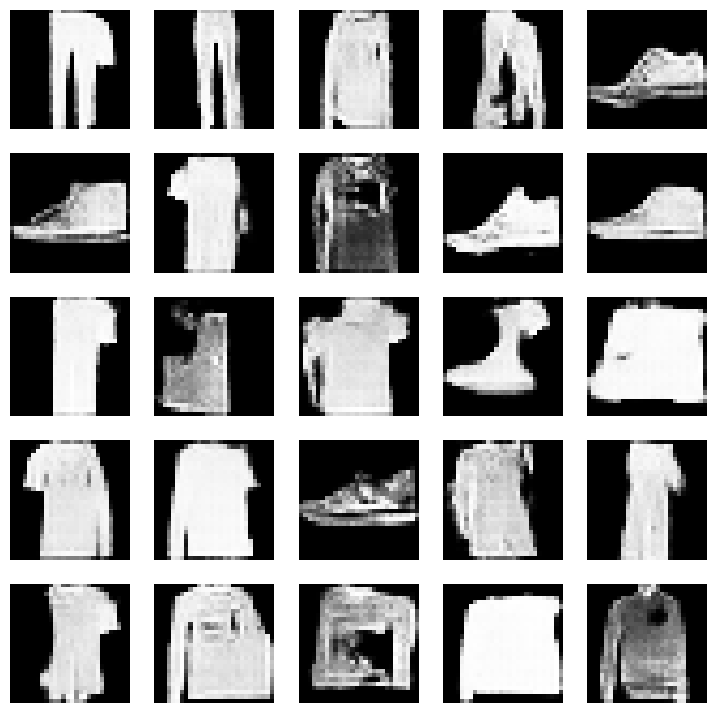

In [12]:
EPOCHS = 30
historico = {"g_loss": [], "d_loss": []}

for epoch in range(EPOCHS):
    dLossSum = gLossSum = dAccSum = gAccSum = 0.0
    cnt = 0

    for batch in dataset:
        # primeiro treina o discriminador, depois o gerador
        d = trainDStep(batch)
        dLossSum += d["discriminator_loss"]
        dAccSum += d["discriminator_accuracy"]

        g = trainGStep(batch)
        gLossSum += g["generator_loss"]
        gAccSum += g["generator_accuracy"]

        cnt += 1

    historico["g_loss"].append(float(gLossSum / cnt))
    historico["d_loss"].append(float(dLossSum / cnt))

    print("Época: {}, Perda G: {:0.4f}, Perda D: {:0.4f}, Acc G: {:0.2f}%, Acc D: {:0.2f}%".format(
        epoch, gLossSum / cnt, dLossSum / cnt,
        100 * gAccSum / cnt, 100 * dAccSum / cnt))

    if (epoch + 1) % 10 == 0:
        plotarImagens(generator, n=5)

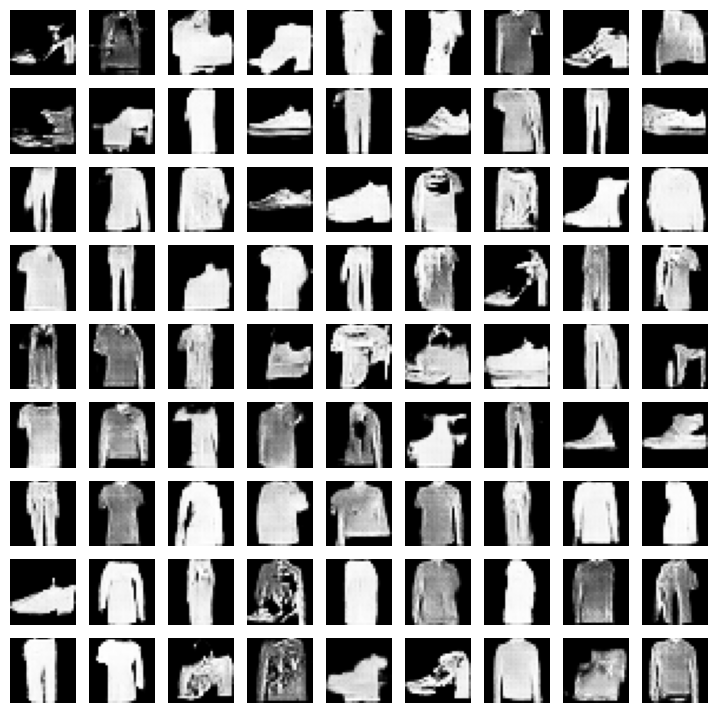

In [13]:
plotarImagens(generator)

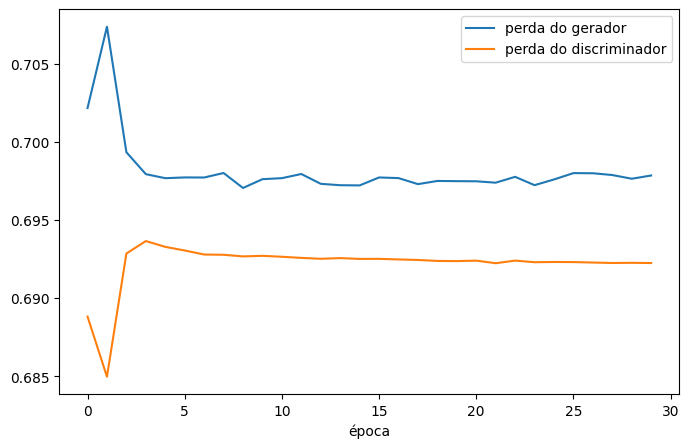

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(historico["g_loss"], label="perda do gerador")
plt.plot(historico["d_loss"], label="perda do discriminador")
plt.xlabel("época")
plt.legend()
plt.show()